# 1. Классические модели для выявления банковских рисков

**Задача:** по тексту новости определить, есть ли сигнал о риске для банка (`alert_flag`: 0 — нет, 1 — есть).

В исследовании использованы Logistic Regression и LinearSVC на признаках TF-IDF. Для контроля использован DummyClassifier.

**Основная метрика — F1-score положительного класса.** Она учитывает одновременно ложные предупреждения и пропущенные риски. Precision, Recall и Average Precision (AP) использую для дополнительного анализа. Модель и порог выбираются на `valid`, а `test` используется только для итоговой проверки.

Сохранён код обучения baseline. Рассчитанные результаты представлены в `03_binary_experiments_comparison.ipynb`.


## 1. Загрузка библиотек и данных

Используется `data/bank_risk_dataset.csv`. Пути определяются относительно каталога проекта. Исходные данные и разбиение train/valid/test сохраняются.

In [1]:
from pathlib import Path
from itertools import product
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display, Markdown
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (precision_recall_curve, average_precision_score,
    precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
# Датасет находится внутри распакованного проекта, в папке data/.
# VS Code может запускать ячейки из рабочей папки, отличной от папки ноутбука.
# Ищем проект рядом с текущей рабочей папкой или выше, не требуя Google Colab.
def find_data_dir():
    current = Path.cwd().resolve()
    locations = [current, *list(current.parents)[:4]]
    for folder in locations:
        if (folder / 'data' / 'bank_risk_dataset.csv').is_file():
            return folder / 'data'
    # Если рабочая папка VS Code — родительская для распакованного архива.
    matches = sorted(current.glob('bank_risk_diploma_results*/data/bank_risk_dataset.csv'))
    if len(matches) == 1:
        return matches[0].parent
    raise FileNotFoundError(
        f'Не найден data/bank_risk_dataset.csv. Текущая папка: {current}. '
        'Рабочий каталог должен содержать data/bank_risk_dataset.csv. '
        ''
    )

DATA_DIR = find_data_dir()
ROOT = DATA_DIR.parent
RESULTS = ROOT / 'results'
MODELS = ROOT / 'models'
RESULTS.mkdir(parents=True, exist_ok=True)
MODELS.mkdir(parents=True, exist_ok=True)
data_path = DATA_DIR / 'bank_risk_dataset.csv'
print('Рабочая папка VS Code:', Path.cwd())
print('Корень проекта:', ROOT)
df = pd.read_csv(data_path)
required = {'text_fragment', 'entity_norm', 'event_group_id', 'split', 'alert_flag', 'sample_id'}
assert required.issubset(df.columns), f'Не найдены столбцы: {required - set(df.columns)}'
assert set(df['split']) == {'train', 'valid', 'test'}
assert df[list(required)].notna().all().all(), 'Есть пропуски в обязательных полях'
assert set(df['alert_flag'].unique()) == {0, 1}
print('Датасет:', data_path)
print('Размер:', df.shape)
display(df[['title', 'entity_norm', 'alert_flag', 'split']].head(3))

Рабочая папка VS Code: d:\bank_risk_diploma_results_v4\bank_risk_diploma_results_v4
Корень проекта: D:\bank_risk_diploma_results_v4\bank_risk_diploma_results_v4
Датасет: D:\bank_risk_diploma_results_v4\bank_risk_diploma_results_v4\data\bank_risk_dataset.csv
Размер: (5041, 12)


,title,entity_norm,alert_flag,split
0,Газпромбанк и РСХБ самоустранились от проекта ...,Росбанк,0,train
1,Хакеры четыре года грабили клиентов Сбербанка ...,ВТБ,1,train
2,"Exxon и ""Роснефть"" прекратили бурение в Арктик...",Газпромбанк,0,train


## 2. Разведочный анализ

В данных преобладает класс «нет риска». Поэтому обычная Accuracy здесь не подходит в качестве основной метрики.

alert_flag,Нет риска,Есть риск
split,,
train,3359,176
valid,715,40
test,713,38


Доля записей с риском: 5.04%
Количество банков: 15
Медианная длина текста (в символах): 532.0


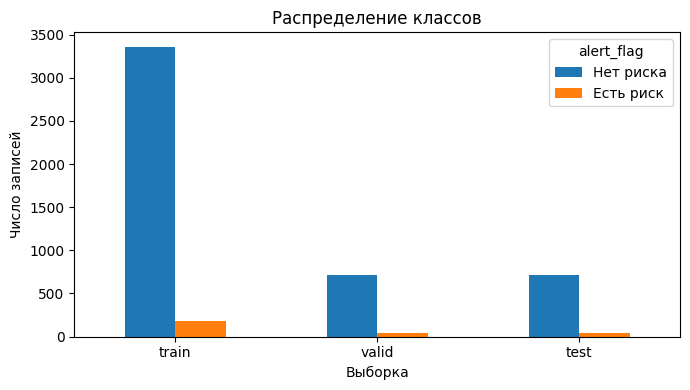

In [2]:
table = pd.crosstab(df['split'], df['alert_flag']).reindex(['train', 'valid', 'test']).rename(columns={0:'Нет риска', 1:'Есть риск'})
display(table)
print('Доля записей с риском:', f"{df['alert_flag'].mean():.2%}")
print('Количество банков:', df['entity_norm'].nunique())
print('Медианная длина текста (в символах):', df['text_fragment'].str.len().median())
ax = table.plot.bar(figsize=(7, 4))
ax.set(xlabel='Выборка', ylabel='Число записей', title='Распределение классов')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [3]:
# Одна группа событий не должна оказаться в разных выборках.
group_overlap = df.groupby('event_group_id')['split'].nunique().gt(1).sum()
normalized = df['text_fragment'].str.lower().str.replace(r'\s+', ' ', regex=True).str.strip()
text_overlap = pd.DataFrame({'text': normalized, 'split': df['split']}).groupby('text')['split'].nunique().gt(1).sum()
print('Пересечений event_group_id:', group_overlap)
print('Точных совпадений нормализованного текста между split:', text_overlap)
assert group_overlap == 0 and text_overlap == 0, 'Обнаружены пересечения между выборками.'
print('Важно: эта проверка не обнаруживает все смысловые дубликаты новостей.')

Пересечений event_group_id: 0
Точных совпадений нормализованного текста между split: 0
Важно: эта проверка не обнаруживает все смысловые дубликаты новостей.


## 3. Подготовка признаков и функций оценки

TF-IDF выделяет слова и пары слов. Дополнительно проверю, помогает ли явно добавить название банка. Служебные поля (`found_risk_keywords`, метки, идентификаторы и даты) в признаки не входят.

Порог для объявления риска подбираю по максимальному F1 на `valid`. Если два порога дают одинаковый F1, выбираю больший, чтобы сократить число ложных тревог.

In [4]:
train = df[df['split'] == 'train'].copy()
valid = df[df['split'] == 'valid'].copy()
test = df[df['split'] == 'test'].copy()

def make_text(frame, with_bank=False):
    text = frame['text_fragment'].astype(str)
    if with_bank:
        return 'Банк: ' + frame['entity_norm'].astype(str) + '. Новость: ' + text
    return text

def raw_scores(model, X):
    if hasattr(model, 'decision_function'):
        return np.asarray(model.decision_function(X))
    return np.asarray(model.predict_proba(X))[:, 1]

def best_threshold(y, scores):
    p, r, thresholds = precision_recall_curve(y, scores)
    f = (2 * p[:-1] * r[:-1]) / np.maximum(p[:-1] + r[:-1], 1e-12)
    best = np.flatnonzero(np.isclose(f, f.max(), rtol=0, atol=1e-12))
    return float(thresholds[best[-1]])

def quality(y, scores, threshold):
    pred = (np.asarray(scores) >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {'f1': f1_score(y, pred, zero_division=0),
            'precision': precision_score(y, pred, zero_division=0),
            'recall': recall_score(y, pred, zero_division=0),
            'ap': average_precision_score(y, scores),
            'tp': int(tp), 'fp': int(fp), 'fn': int(fn), 'tn': int(tn)}

## 4. Обучение и подбор параметров

Перебор ограниченный, чтобы эксперимент было легко повторить. У каждого алгоритма выберу лучший вариант **по F1 на validation**, а при равенстве — по AP. Результаты на test в выборе не участвуют.

In [5]:
# TF-IDF обучается только на train.
prepared = {}
for with_bank, ngrams in product([False, True], [(1, 1), (1, 2)]):
    vec = TfidfVectorizer(ngram_range=ngrams, min_df=2, max_df=0.99,
                          max_features=70_000, sublinear_tf=True)
    X_tr = vec.fit_transform(make_text(train, with_bank))
    X_va = vec.transform(make_text(valid, with_bank))
    prepared[(with_bank, ngrams)] = (vec, X_tr, X_va)

experiments = []
trained = {}
for family in ['LogisticRegression', 'LinearSVC']:
    for (with_bank, ngrams), (vec, X_tr, X_va) in prepared.items():
        for class_weight, C in product([None, 'balanced'], [0.1, 1.0, 3.0]):
            if family == 'LogisticRegression':
                clf = LogisticRegression(C=C, class_weight=class_weight,
                                         max_iter=2000, random_state=SEED)
            else:
                clf = LinearSVC(C=C, class_weight=class_weight, random_state=SEED)
            clf.fit(X_tr, train['alert_flag'])
            scores = raw_scores(clf, X_va)
            threshold = best_threshold(valid['alert_flag'], scores)
            row = dict(model=family, with_bank=with_bank, ngrams=str(ngrams),
                       class_weight=str(class_weight), C=C, threshold=threshold,
                       **quality(valid['alert_flag'], scores, threshold))
            experiments.append(row)
            key = len(experiments)-1
            trained[key] = (clf, vec, with_bank)

search = pd.DataFrame(experiments)
search['experiment_id'] = np.arange(len(search))
best = (search.sort_values(['f1', 'ap'], ascending=False)
              .drop_duplicates('model').set_index('model'))
print('Лучшие классические модели на validation:')
display(best[['with_bank', 'ngrams', 'class_weight', 'C', 'threshold', 'f1', 'precision', 'recall', 'ap']].round(4))
winner = best.sort_values(['f1', 'ap'], ascending=False).index[0]
print('Лучшая классическая модель по validation F1:', winner)

Лучшие классические модели на validation:


,with_bank,ngrams,class_weight,C,threshold,f1,precision,recall,ap
model,,,,,,,,,
LinearSVC,False,"(1, 1)",balanced,0.1,0.0100,0.7532,0.7838,0.725,0.7561
LogisticRegression,False,"(1, 1)",balanced,3.0,-0.0731,0.7273,0.7568,0.700,0.7606


Лучшая классическая модель по validation F1: LinearSVC


## 5. Результаты на test

Оцениваю отобранные модели и DummyClassifier. Для Dummy тоже выбираю порог на validation. После этого пороги не меняются.

In [6]:
result_rows = []
prediction_table = test[['sample_id', 'event_group_id', 'entity_norm', 'alert_flag']].copy()
for family, selected in best.iterrows():
    clf, vec, with_bank = trained[int(selected['experiment_id'])]
    pipeline = Pipeline([('tfidf', vec), ('classifier', clf)])
    threshold = float(selected['threshold'])
    for split_name, part in [('valid', valid), ('test', test)]:
        scores = raw_scores(pipeline, make_text(part, with_bank))
        result_rows.append(dict(model=family, split=split_name,
                                threshold=threshold, **quality(part['alert_flag'], scores, threshold)))
        if split_name == 'test':
            prediction_table[f'{family}_score'] = scores
            prediction_table[f'{family}_pred'] = (scores >= threshold).astype(int)
    joblib.dump({'pipeline': pipeline, 'threshold': threshold, 'with_bank': with_bank},
                MODELS / f'{family}.joblib')

dummy = DummyClassifier(strategy='prior')
dummy.fit(np.zeros((len(train), 1)), train['alert_flag'])
va_scores = dummy.predict_proba(np.zeros((len(valid), 1)))[:, 1]
dummy_threshold = best_threshold(valid['alert_flag'], va_scores)
for split_name, part in [('valid', valid), ('test', test)]:
    scores = dummy.predict_proba(np.zeros((len(part), 1)))[:, 1]
    result_rows.append(dict(model='DummyClassifier', split=split_name,
                            threshold=dummy_threshold, **quality(part['alert_flag'], scores, dummy_threshold)))
metrics = pd.DataFrame(result_rows)
print('Validation:')
display(metrics[metrics['split']=='valid'].round(4))
print('Test:')
display(metrics[metrics['split']=='test'].round(4))

Validation:


,model,split,threshold,f1,precision,recall,ap,tp,fp,fn,tn
0,LinearSVC,valid,0.0100,0.7532,0.7838,0.725,0.7561,29,8,11,707
2,LogisticRegression,valid,-0.0731,0.7273,0.7568,0.700,0.7606,28,9,12,706
4,DummyClassifier,valid,0.0498,0.1006,0.0530,1.000,0.0530,40,715,0,0


Test:


,model,split,threshold,f1,precision,recall,ap,tp,fp,fn,tn
1,LinearSVC,test,0.0100,0.8642,0.8140,0.9211,0.9427,35,8,3,705
3,LogisticRegression,test,-0.0731,0.8861,0.8537,0.9211,0.9476,35,6,3,707
5,DummyClassifier,test,0.0498,0.0963,0.0506,1.0000,0.0506,38,713,0,0


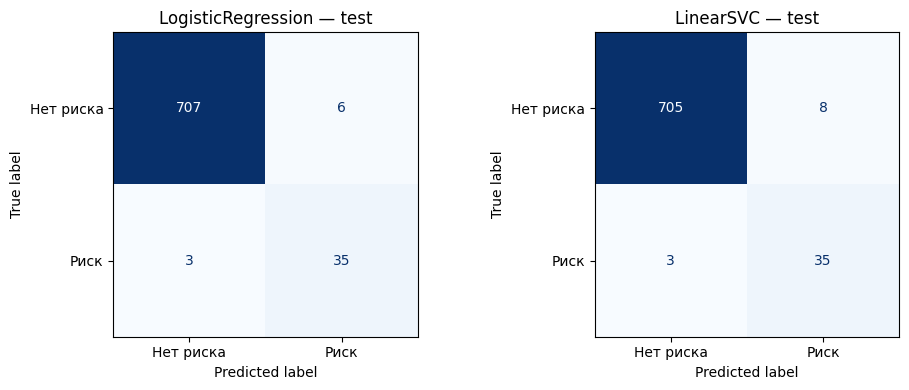

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, family in zip(axes, ['LogisticRegression', 'LinearSVC']):
    r = metrics[(metrics['model']==family)&(metrics['split']=='test')].iloc[0]
    matrix = np.array([[r.tn, r.fp], [r.fn, r.tp]], dtype=int)
    ConfusionMatrixDisplay(matrix, display_labels=['Нет риска', 'Риск']).plot(
        ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{family} — test')
plt.tight_layout()
plt.show()

## 6. Анализ ошибок и сохранение результатов

Ложное предупреждение (FP) — модель нашла риск там, где в разметке его нет. Пропуск (FN) — не обнаружила отмеченный риск. Возможные ошибки разметки не исправляю на основе тестовых результатов.

In [8]:
selected = best.loc[winner]
clf, vec, with_bank = trained[int(selected['experiment_id'])]
pred = prediction_table[f'{winner}_pred'].to_numpy()
error_review = test[['sample_id', 'title', 'entity_norm', 'alert_flag']].copy()
error_review['pred'] = pred
print('Ложные тревоги:')
display(error_review[(error_review['alert_flag']==0) & (error_review['pred']==1)].head(5))
print('Пропущенные риски:')
display(error_review[(error_review['alert_flag']==1) & (error_review['pred']==0)].head(5))

search.to_csv(RESULTS/'baseline_validation_search.csv', index=False)
metrics.to_csv(RESULTS/'baseline_metrics.csv', index=False)
prediction_table.to_csv(RESULTS/'baseline_test_predictions.csv', index=False)
print('Файлы сохранены в:', RESULTS)

Ложные тревоги:


,sample_id,title,entity_norm,alert_flag,pred
184,ml_nat5_final_000185,ФСБ Петербурга увидела умышленное неисполнение...,ВТБ,0,1
653,ml_nat5_final_000654,"Сбербанк подтвердил информацию, что часть анке...",Сбербанк,0,1
970,ml_nat5_final_000971,Греф оценил потери Сбербанка от подделок пятит...,ВТБ,0,1
1001,ml_nat5_final_001002,Райффайзенбанк попросил клиентов воздержаться ...,Райффайзенбанк,0,1
1054,ml_nat5_final_001055,Альфа-банк сообщил о временных проблемах в про...,Альфа-Банк,0,1


Пропущенные риски:


,sample_id,title,entity_norm,alert_flag,pred
469,ml_nat5_final_000470,"Арбитраж подтвердил законность штрафа, наложен...",ВТБ,1,0
798,ml_nat5_final_000799,Суд в Новосибирске отменил решение об освобожд...,ВТБ,1,0
812,ml_nat5_final_000813,ОНФ просит проверить Россельхозбанк на мошенни...,Россельхозбанк,1,0


Файлы сохранены в: D:\bank_risk_diploma_results_v4\bank_risk_diploma_results_v4\results


## 7. Выводы

Основная метрика исследования — **F1**, поэтому победитель выбирается по F1 на validation, а не по AP на test. По Precision, Recall и AP оцениваю компромиссы.

При интерпретации нужно помнить, что положительных примеров мало, в данных возможны спорные метки и смысловые повторы, а исходное разбиение не временное. Тестовый набор уже использовался в более ранних экспериментах, поэтому результаты этого исследования нельзя считать новым независимым подтверждением.

In [9]:
v = metrics[(metrics.model==winner)&(metrics.split=='valid')].iloc[0]
t = metrics[(metrics.model==winner)&(metrics.split=='test')].iloc[0]
display(Markdown(
    f'**Итог:** лучшая классическая модель по validation F1 — **{winner}** '
    f'(F1 = **{v.f1:.4f}**). На test: F1 = **{t.f1:.4f}**, '
    f'Precision = **{t.precision:.4f}**, Recall = **{t.recall:.4f}**, '
    f'AP = **{t.ap:.4f}**, FP = **{int(t.fp)}**, FN = **{int(t.fn)}**.'))

**Итог:** лучшая классическая модель по validation F1 — **LinearSVC** (F1 = **0.7532**). На test: F1 = **0.8642**, Precision = **0.8140**, Recall = **0.9211**, AP = **0.9427**, FP = **8**, FN = **3**.